# 13 - ML Curve Imputation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/13_ml_curve_imputation.ipynb)

**Part B - Petrophys Curriculum**

Real well-log data is full of holes: a tool fails over an interval, a curve was
only run over part of the hole, or it was never run at all. Classic fixes -
interpolation, constant fill, or dropping the interval - either invent structure
or throw away depth. **Machine-learning curve imputation** instead *predicts* the
missing samples from the curves that **are** present, by learning how the logs
relate to each other where all of them were measured.

In `petrophys` this is one function, `pp.impute(well, curve)`. It trains a
gradient-boosted tree model on the fly, from this well and any offset wells you
pass, and fills the gaps of one curve. This lesson shows how to:

- Blank a block of a real, measured curve, rebuild it, and **score the
  prediction against the values we hid**.
- Fill a well's **genuine** gaps, and read the warning `pp.impute` gives when
  the gap lies outside what the model has seen.
- **Rebuild a curve a well does not have** from offset wells in the same field.
- Write the result to a LAS file with `output=`.
- Decide *when* imputation is appropriate and *when it is risky*.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- Call `pp.impute(well, curve)` and find its result in the `<CURVE>_IMPUTED`
  curve, with the measured samples left exactly as recorded.
- Read the check `pp.impute` runs on every call: `<CURVE>_PREDICTED`, each
  measured sample predicted by a model that did not learn from its part of the
  well, with the mean absolute error, bias and $R^2$ in its description.
- Read the extrapolation warning and trace it back to the input logs that cause it.
- Rebuild an absent curve with `train_wells=` and judge the result with a blind
  test.
- Write an imputed well to LAS with `output=` and read it back.
- Explain the appropriateness and the risks of ML curve imputation.

## How `pp.impute` works

```python
pp.impute(well, curve, *, train_wells=None, output=None) -> Well
```

`well` can also be a well file or an interpretation result; `pp.impute` returns
what it was given, so a result comes back as a result.

1. **Training data.** Wherever `curve` was measured - in `well` itself and in
   every well in `train_wells` - the measured values become the training targets.
2. **Inputs.** The other logs are the inputs: whichever of GR, SP, CALI, BS,
   RHOB, DRHO, NPHI, PEF, DTC, DTS, RDEP, RMED, RSHA and RXO are present where
   the curve is missing and in every training well. Depth is *not* an input.
3. **Model.** A scikit-learn `HistGradientBoostingRegressor` is fitted to that
   data each time you call the function. Nothing is stored between calls.
   Resistivity targets are modelled as $\log_{10}$, since they span decades.
4. **Output.** The well gains `<CURVE>_IMPUTED`: the measured values where the
   curve has them, the predictions in its gaps. The original curve is untouched.
   With `output=` the well is also written to a LAS file.
5. **Check.** The well also gains `<CURVE>_PREDICTED`, a prediction at every
   depth. At measured depths it is a blank-and-restore test: the well is cut
   into five contiguous depth blocks, and each block is predicted by a model
   trained without that block (the training wells are always used). Its
   description gives the mean absolute error, bias and $R^2$ against the
   measured curve.

Three rules follow from this design:

- **A curve the well does not have needs `train_wells`.** With nothing measured
  in the well itself, the model can only learn from other wells; without them
  `pp.impute` raises `ValueError`.
- **At least 200 measured samples** are needed to train, otherwise `ValueError`.
- **Trees do not extrapolate.** Where an input log falls outside the range it
  had in the training data, the prediction stays near the edge of what the
  model has seen. `pp.impute` warns with the number of such samples.

### Prerequisites

Assumes the Part A loading/QAQC lessons (01, 02). `pp.impute` needs
scikit-learn, which the machine-learning extra installs. Install it in the same
environment as the notebook kernel:

```bash
pip install "petrophys[ml]"
```

In [2]:
import copy
import tempfile
from pathlib import Path

import pandas as pd
import petrophys as pp

pd.set_option("display.precision", 3)

## 1. The built-in check: blank, impute, score

We load **15/9-14**, a GeoLink North Sea well whose neutron log (`NPHI`) was
recorded over almost the whole hole (480-3575 m; two samples are missing).
`pp.impute` fills those two samples, and it also blanks each fifth of the
measured log in turn - about 620 m at a time - rebuilds it from a model trained
on the other four fifths, and scores the result against the values it hid.

In [3]:
well = pp.impute(pp.read(pp.sample("15_9-14")), "NPHI")
well["NPHI_PREDICTED"].description

'NPHI predicted at every depth; at measured depths by a model that did not learn from that part of the well (5 depth blocks): mean absolute error 0.0893, bias +0.0296, R2 0.19 against 20281 measured samples'

No extrapolation warning appears: the inputs at the two gap samples lie inside
the training range. The check says much more: over 20,281 measured samples the
out-of-block prediction is off by 0.089 v/v on average (mean absolute error),
reads 0.030 v/v high (bias), and explains only 0.19 of the variance ($R^2$).

That is a strict test, and an honest one. Each blind block is a fifth of the
well: a long depth section, with its own compaction and rock types, that the
model never saw. The check gives the error to expect for gaps that long. A short
drop-out inside well-sampled rock is easier, but no single easy interval is a
verdict; carry the typical error, not the best case.

`pp.plot` draws the measured curve and its prediction in one track, the
prediction in black. Shales read above 0.45 v/v here, so `curve_styles` widens
the neutron scale:

[repository]\src\petrophys\visualization\log_viewer.py:1984: DataQualityWarning: DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.
  standardize_curves(
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1138: DataQualityWarning: RSHA: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1138: DataQualityWarning: RXO: 6 of 4059 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1138: DataQualityWarning: RMED: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.

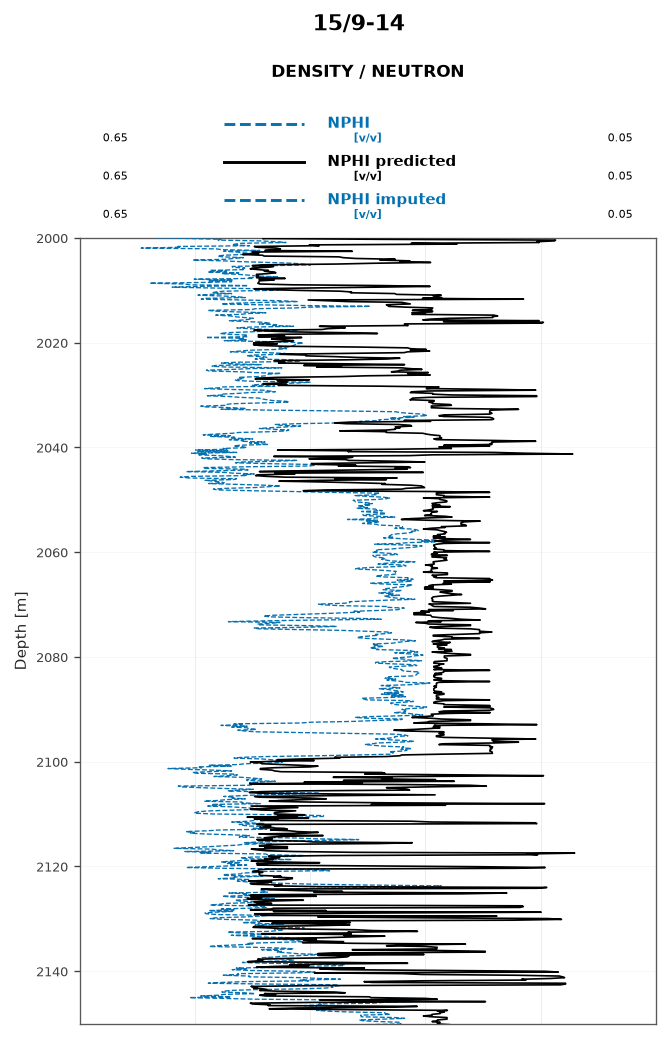

In [4]:
scale = {"left": 0.65, "right": 0.05}
pp.plot(well, curves=["NPHI", "NPHI_PREDICTED"], top=2000, bottom=2150, figsize=(5, 9),
        curve_styles={name: scale for name in ["NPHI", "NPHI_PREDICTED", "NPHI_IMPUTED"]}).show()

In the sand between about 2050 and 2100 m the prediction follows the shape of
the measured neutron but reads about 0.07 v/v low. In the shales above and below it, where NPHI reads 0.45-0.55,
the prediction is noisy and swings far too low, to 0.2 and less: the other
logs do not pin down shale neutron porosity across a fifth of the well. That is
where most of the error in the description comes from.

## 2. Filling a well's genuine gaps - and reading the warning

**16/7-1** has a real gap: its density log (`RHOB`) was only recorded over the
lower part of the hole. `pp.impute` reads the file itself.

In [5]:
w167 = pp.impute(pp.sample("16_7-1"), "RHOB")
w167["RHOB_PREDICTED"].description

[temporary directory]\ipykernel_18784\1678103776.py:1: UserWarning: 16/7-1: 7006 of 7006 imputed RHOB samples have input logs outside the range of the training data, where the model cannot extrapolate
  w167 = pp.impute(pp.sample("16_7-1"), "RHOB")


'RHOB predicted at every depth; at measured depths by a model that did not learn from that part of the well (5 depth blocks): mean absolute error 0.0716, bias -0.0112, R2 0.50 against 7980 measured samples'

The check scores the model where RHOB was measured: mean absolute error
0.072 g/cm3, bias -0.011 g/cm3, $R^2$ 0.50 over 7980 samples. It cannot
score the gap itself, which has no measurement, and the warning says every
imputed sample there is flagged. To see why, compare each input log where RHOB
was measured (the training data) with the same log in the gap: the number of
samples it has in each part (`count`) and its median.

In [6]:
logs = w167.to_dataframe(["GR", "SP", "CALI", "BS", "DTC", "RDEP", "RMED", "RSHA", "RHOB"], include_depth=False)
logs.groupby(logs["RHOB"].isna().map({False: "RHOB measured", True: "RHOB gap"})).agg(["count", "median"]).T

RHOB         RHOB gap  RHOB measured
GR   count   6961.000       7910.000
     median    86.475         13.862
SP   count   7005.000       7980.000
     median    79.032         75.580
CALI count   7006.000       7980.000
     median    12.020          9.879
BS   count   7006.000       7980.000
     median    12.250          8.500
DTC  count   1620.000       7807.000
     median    44.831         24.545
RDEP count   6957.000       7820.000
     median     1.197          1.162
RMED count   6961.000        140.000
     median     1.399          0.781
RSHA count   6961.000       7977.000
     median     1.117          1.117
RHOB count      0.000       7980.000
     median       NaN          2.087

The table tells the geological story behind the warning:

- **BS (bit size).** The shallow gap was drilled with a 12.25 in bit, the
  section where density was logged with an 8.5 in bit, so every gap sample has
  a bit size the model has never seen.
- **RMED.** The medium resistivity was recorded almost only in the shallow
  section: 140 samples where RHOB was measured against 6961 in the gap, so the
  model has learned very little about it.
- **GR.** The measured-density section is dominated by low-GR evaporites
  (median GR 14 API; the Zechstein salt, which case study CS4 shows), while the
  gap is shallow, higher-GR mudstone (median 86 API). The model learned density
  from different rocks.

So the check's error belongs to the rocks where density was measured; it is not
the error of the gap. `pp.impute` produces numbers anyway, and the plot below
shows that they look like a density log. But they are a guess outside the
model's experience: here the imputed shallow RHOB should not be used for
porosity.

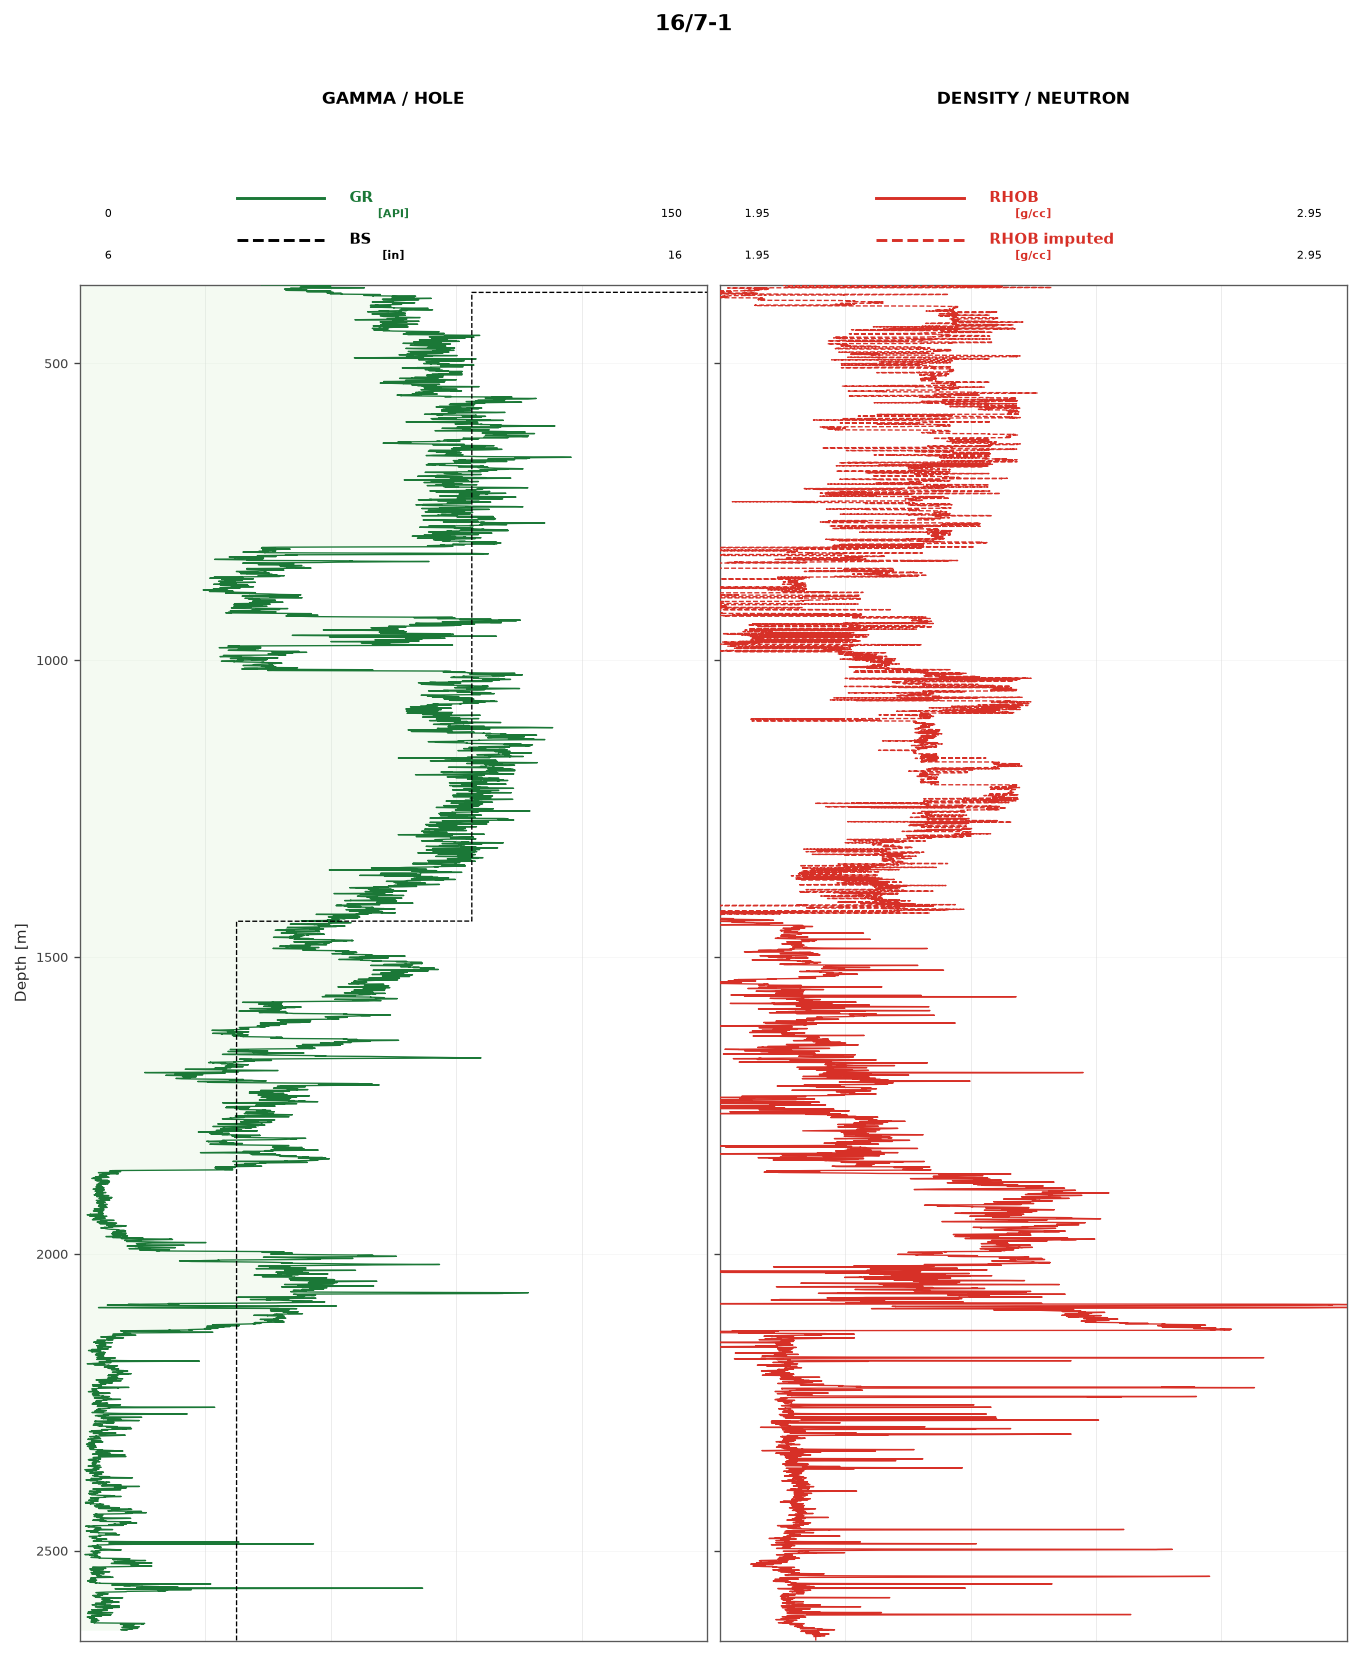

In [7]:
pp.plot(w167, curves=["GR", "BS", "RHOB", "RHOB_IMPUTED"]).show()

The whole well is shown so that the gap (above about 1430 m, where the bit size
steps from 12.25 to 8.5 in) and the measured section can be compared: the
imputed density (dashed) fills the gap, the measured density runs below it.

## 3. Learning from offset wells

With **training wells** from the same field, the model learns from rocks the
target well may not sample well. The bundled **COSTA** dataset gives us 17
wells (HW-*) from one field. `pp.list_samples("costa")` names them and
`pp.read` reads the list. Not every well carries sonic (`DT`) data:

In [8]:
costa = pp.read([pp.sample(name) for name in pp.list_samples("costa")])
costa["HW-24"].curves, sum(w.get("DT").valid_count() > 0 for w in costa)

(['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC'], 7)

Only 7 of the 17 wells carry DT, so a sonic model learns from far fewer wells
than a density or neutron model, which all 17 carry. We impute three curves,
each in a different well, with all the *other* COSTA wells as training wells.
The check of each blanks a fifth of the target well at a time; the 16 other
wells always stay in the training data. The three curves have no gaps, so
`pp.impute` warns that `_IMPUTED` is the measured curve: here we want the check.

In [9]:
cases = [("HW-24", "RHOB"), ("HW-31", "NPHI"), ("HW-27", "DT")]
{f"{name} {curve}": pp.impute(costa[name], curve, train_wells=[w for w in costa if w.name != name])
 [curve + "_PREDICTED"].description.split(": ")[1] for name, curve in cases}

[temporary directory]\ipykernel_18784\3264780736.py:2: UserWarning: HW-24: RHOB has no missing samples; RHOB_IMPUTED is the measured curve, and RHOB_PREDICTED checks the model against it
  {f"{name} {curve}": pp.impute(costa[name], curve, train_wells=[w for w in costa if w.name != name])


[temporary directory]\ipykernel_18784\3264780736.py:2: UserWarning: HW-31: NPHI has no missing samples; NPHI_IMPUTED is the measured curve, and NPHI_PREDICTED checks the model against it
  {f"{name} {curve}": pp.impute(costa[name], curve, train_wells=[w for w in costa if w.name != name])


[temporary directory]\ipykernel_18784\3264780736.py:2: UserWarning: HW-27: DT has no missing samples; DT_IMPUTED is the measured curve, and DT_PREDICTED checks the model against it
  {f"{name} {curve}": pp.impute(costa[name], curve, train_wells=[w for w in costa if w.name != name])


{'HW-24 RHOB': 'mean absolute error 0.0346, bias +0.00016, R2 0.89 against 433 measured samples',
 'HW-31 NPHI': 'mean absolute error 0.0146, bias -0.00398, R2 0.95 against 412 measured samples',
 'HW-27 DT': 'mean absolute error 3.74, bias +2.33, R2 0.81 against 409 measured samples'}

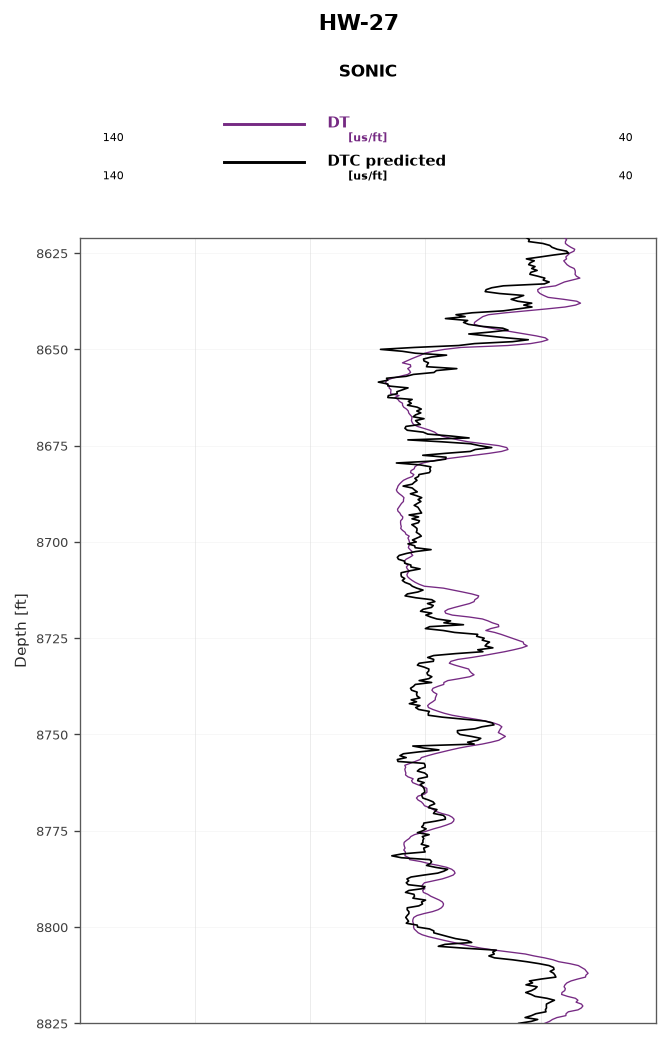

In [10]:
pp.plot(costa["HW-27"], curves=["DT", "DT_PREDICTED"], figsize=(5, 9)).show()

In one field with consistent logging, density and neutron are predicted well
($R^2$ 0.89 and 0.95), because they are strongly coupled to each other and to
the gamma ray. The sonic is harder: only 6 other wells carry it, so the model
has less to learn from. The prediction of HW-27's DT follows the main breaks
but reads slow (bias +2.3 us/ft, $R^2$ 0.81), mostly in the fast, tight beds
near 8630 and 8720 ft and below 8805 ft, where the prediction does not reach
the low measured transit times.

### A blind test: a well that never had the curve

The check always keeps four fifths of the target's own curve in the training
data. A well that never ran a sonic has none of it. To measure that case we
remove DT from a copy of HW-27, rebuild it from the other wells alone, and
compare with the removed log. Without training wells, a curve the well does
not have raises `ValueError: ... has no ... curve; pass train_wells= with wells
that have it`.

In [11]:
blind = copy.deepcopy(costa["HW-27"])
blind.remove_curve("DT")
blind = pp.impute(blind, "DT", train_wells=[w for w in costa if w.name != "HW-27"])
error = pd.Series(blind["DT_IMPUTED"].data - costa["HW-27"]["DT"].data)
pd.Series({"mean absolute error": error.abs().mean(), "bias": error.mean(), "samples": error.count()})

[temporary directory]\ipykernel_18784\1712802947.py:3: UserWarning: HW-27: 40 of 409 imputed DT samples have input logs outside the range of the training data, where the model cannot extrapolate
  blind = pp.impute(blind, "DT", train_wells=[w for w in costa if w.name != "HW-27"])


mean absolute error      6.402
bias                     6.380
samples                409.000
dtype: float64

Rebuilt from the other wells alone, DT reads 6.4 us/ft slow on average over
409 samples, and the bias makes up almost all of the 6.4 us/ft mean absolute
error: three times the check's +2.3 us/ft. With four fifths of its own sonic in
the training data, the model corrects most of that offset; a well that never
ran the tool has no such correction, and only a blind test like this one
measures that case. Same function, same field - the quality depends on how much
training data there is, whether the well itself contributes, and how strongly
the curve is tied to the inputs.

Offset wells only help when they resemble the target. Wells from another basin,
or from a different part of the stratigraphy, teach the model the wrong
relations, and the extrapolation warning will only catch the part of that
mismatch that shows up as out-of-range inputs.

## 4. File-in / file-out with `output=`

For batch or pipeline use, `pp.impute` also accepts a file path for the well
and writes the result to LAS when you pass `output=`. Here we impute the 16/7-1
RHOB straight from the bundled file into a LAS file in a temporary folder and
read it back.

In [12]:
las_path = Path(tempfile.mkdtemp()) / "16_7-1_rhob_imputed.las"
pp.impute(pp.sample("16_7-1"), "RHOB", output=las_path)
back = pp.read(las_path)
back.curves, back.get("RHOB").null_count(), back.get("RHOB_IMPUTED").null_count()

[temporary directory]\ipykernel_18784\1899256372.py:2: UserWarning: 16/7-1: 7006 of 7006 imputed RHOB samples have input logs outside the range of the training data, where the model cannot extrapolate
  pp.impute(pp.sample("16_7-1"), "RHOB", output=las_path)


(['LITHOLOGY_GEOLINK',
  'DCAL',
  'CALI',
  'BS',
  'DRHO',
  'RHOB',
  'GR',
  'DTC',
  'RDEP',
  'SP',
  'RSHA',
  'RMED',
  'RHOB_PREDICTED',
  'RHOB_IMPUTED'],
 7006,
 0)

The LAS keeps the measured `RHOB` with its gap (7006 null samples) and adds
`RHOB_IMPUTED` beside it, complete, so anyone opening the file can still tell
measured from modelled samples: they are the samples where `RHOB` is null.
`RHOB_PREDICTED` travels with them, with its check in the curve description.

## 5. When is imputation appropriate - and when is it risky?

**Appropriate**

- Short tool drop-outs or a partly recorded curve, *when the companion logs are
  present and of good quality* over both the gap and the measured section.
- The gap lies in rocks the training data samples: the same formations, the
  same hole size and logging conditions. No extrapolation warning, or only a
  handful of flagged samples.
- Rebuilding an absent curve from **offset wells in the same field**, validated
  first by removing the curve from one of those wells (section 3).
- You keep the measured and the imputed curves side by side, and every
  downstream result says which samples were modelled.

**Risky / inappropriate**

- **Extrapolation.** A gap in a different rock, depth range or hole size than
  the training data (section 2). The warning counts these samples; when it
  flags most of them, treat the result as a guess.
- **Offset wells from another field or basin.** They can share curve names and
  still have different rocks, fluids and tools.
- **Bad inputs.** A mis-scaled or washed-out companion log feeds straight into
  the prediction. Quality-control the inputs first (lesson 02).
- **Circular use.** Never use an imputed curve as if it were measured in a
  saturation or net-pay calculation without stating its uncertainty. The
  `_PREDICTED` error of one well is an estimate for rocks like those measured,
  not a calibrated bound for other intervals.
- **Small training sets.** Below 200 measured samples `pp.impute` refuses to
  train; just above that, the model is still poorly constrained.

## Recap

- `pp.impute(well, curve)` trains a gradient-boosted tree model on the fly and
  adds `<CURVE>_IMPUTED`: measured values kept exactly, predictions in the gaps.
- Every call also adds `<CURVE>_PREDICTED`, a blank-and-restore check by depth
  blocks; on 15/9-14 NPHI it shows how weak a prediction across a fifth of the
  well can be.
- The **extrapolation warning** on the 16/7-1 RHOB gap traces back to a larger
  bit size, a resistivity curve absent from the training section and different
  rocks: the check scores the measured section, and the gap-fill there is not
  usable for porosity.
- **`train_wells=`** brings in offset wells. In the COSTA field, density and
  neutron are predicted well; the sonic, with fewer wells to learn from, less
  so, and worse again in a blind test where the well never had the curve.
- **`output=`** writes the well, measured and imputed curves side by side, to LAS.

## Try it yourself

> **Exercise 1.** Impute `RHOB` and `DTC` of 15/9-14 and compare the errors in
> their `_PREDICTED` descriptions with NPHI's. Which curves impute most
> accurately, and why? (Hint: think about how strongly each is coupled to the
> other logs.)
>
> **Exercise 2.** Reduce the companion information: remove `RHOB` and `DTC`
> from a copy of 15/9-14 with `remove_curve` before imputing NPHI. How does the
> check's error respond as inputs disappear?
>
> **Exercise 3.** Repeat the blind DT test on HW-27 with only three COSTA
> wells for training instead of 16. How much worse is the result? Then try
> training HW-24 RHOB on GeoLink North Sea wells (`pp.sample("15_9-14")`,
> `"25_5-1"`, `"30_6-5"`) instead: what does the warning say, and what happens
> to the check's $R^2$?

## What's next

You have seen the two complementary ways of extending sparse measurements
across a well: physics-based core calibration (lesson 12) and data-driven ML
imputation (this lesson). Continue with **14 - NMR Petrophysics**, which
interprets a real CMR log: bound versus free fluid, irreducible saturation and
NMR permeability.